In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import soundfile as sf

In [2]:
metadata_path = "../data/raw/ESC-50/meta/esc50.csv"

df = pd.read_csv(metadata_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head()

,filename,fold,target,category,esc10,src_file,take
0,1-100032-A-0.wav,1,0,dog,True,100032,A
1,1-100038-A-14.wav,1,14,chirping_birds,False,100038,A
2,1-100210-A-36.wav,1,36,vacuum_cleaner,False,100210,A
3,1-100210-B-36.wav,1,36,vacuum_cleaner,False,100210,B
4,1-101296-A-19.wav,1,19,thunderstorm,False,101296,A


In [4]:
print("Total rows:", len(df))
print("Total columns:", len(df.columns))

df.info()

Total rows: 2000
Total columns: 7
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   filename  2000 non-null   str  
 1   fold      2000 non-null   int64
 2   target    2000 non-null   int64
 3   category  2000 non-null   str  
 4   esc10     2000 non-null   bool 
 5   src_file  2000 non-null   int64
 6   take      2000 non-null   str  
dtypes: bool(1), int64(3), str(3)
memory usage: 95.8 KB


In [5]:
df.columns

Index(['filename', 'fold', 'target', 'category', 'esc10', 'src_file', 'take'],
      dtype='str')

In [6]:
print("Total unique categories:", df["category"].nunique())

print("\nCategories:")
print(df["category"].unique())

Total unique categories: 50

Categories:
<StringArray>
[             'dog',   'chirping_birds',   'vacuum_cleaner',
     'thunderstorm',  'door_wood_knock',      'can_opening',
             'crow',         'clapping',        'fireworks',
         'chainsaw',         'airplane',      'mouse_click',
    'pouring_water',            'train',            'sheep',
      'water_drops',     'church_bells',      'clock_alarm',
  'keyboard_typing',             'wind',        'footsteps',
             'frog',              'cow',   'brushing_teeth',
         'car_horn',   'crackling_fire',       'helicopter',
 'drinking_sipping',             'rain',          'insects',
         'laughing',              'hen',           'engine',
        'breathing',      'crying_baby',         'hand_saw',
         'coughing',   'glass_breaking',          'snoring',
     'toilet_flush',              'pig',  'washing_machine',
       'clock_tick',         'sneezing',          'rooster',
        'sea_waves',          

In [7]:
class_counts = df["category"].value_counts()

print(class_counts)

category
dog                 40
chirping_birds      40
vacuum_cleaner      40
thunderstorm        40
door_wood_knock     40
can_opening         40
crow                40
clapping            40
fireworks           40
chainsaw            40
airplane            40
mouse_click         40
pouring_water       40
train               40
sheep               40
water_drops         40
church_bells        40
clock_alarm         40
keyboard_typing     40
wind                40
footsteps           40
frog                40
cow                 40
brushing_teeth      40
car_horn            40
crackling_fire      40
helicopter          40
drinking_sipping    40
rain                40
insects             40
laughing            40
hen                 40
engine              40
breathing           40
crying_baby         40
hand_saw            40
coughing            40
glass_breaking      40
snoring             40
toilet_flush        40
pig                 40
washing_machine     40
clock_tick          40
sn

In [8]:
print("Minimum recordings:", class_counts.min())
print("Maximum recordings:", class_counts.max())

if class_counts.min() == class_counts.max():
    print("Dataset is balanced")
else:
    print("Dataset is imbalanced")

Minimum recordings: 40
Maximum recordings: 40
Dataset is balanced


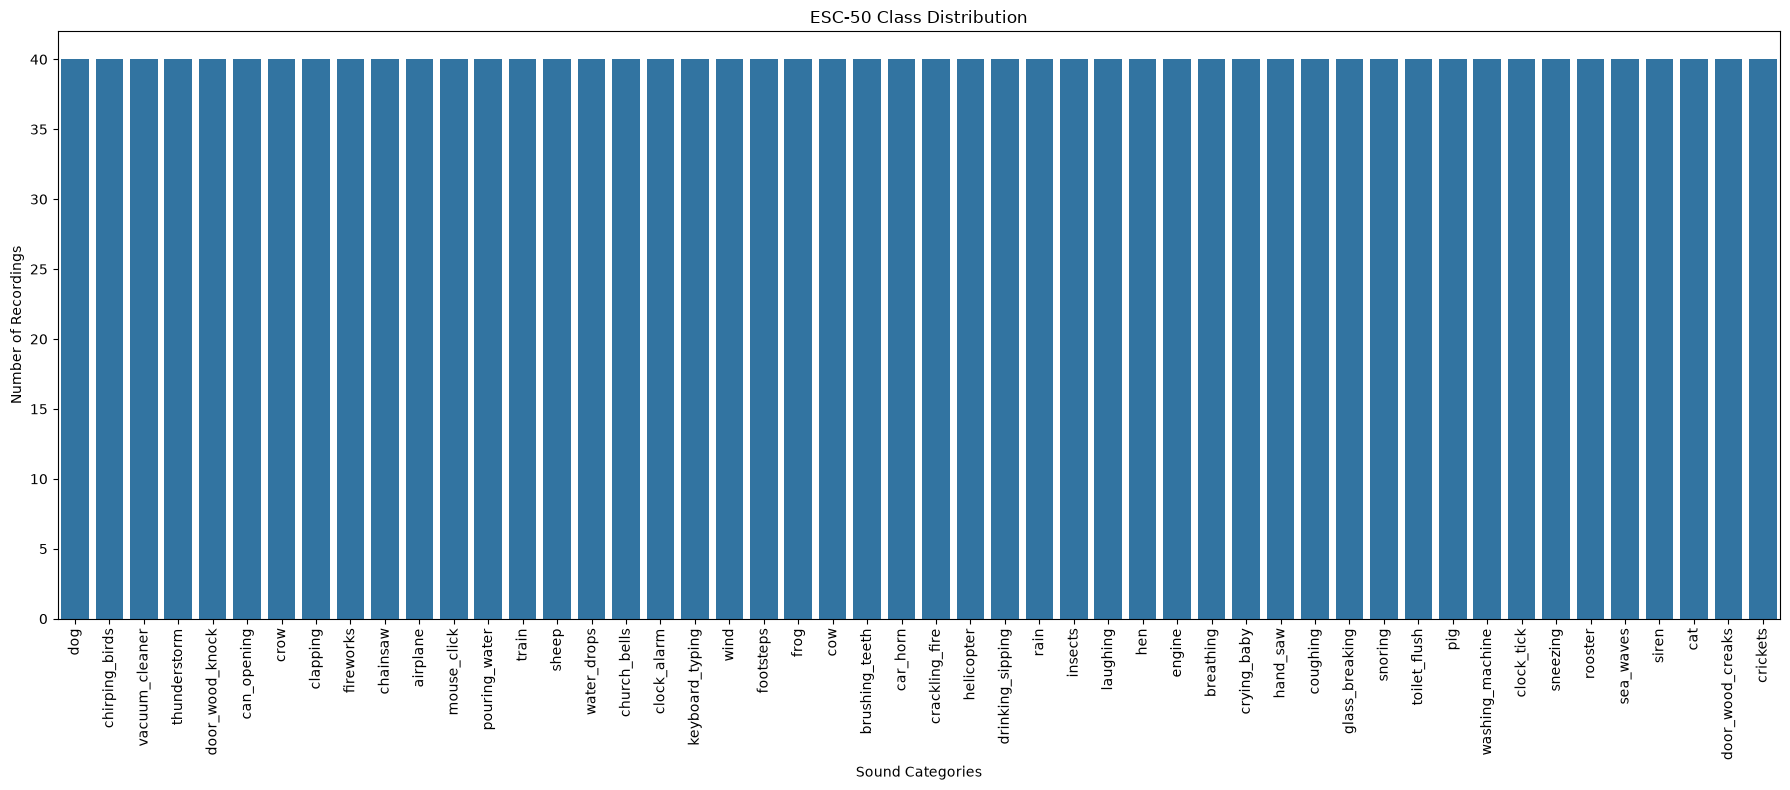

In [9]:
plt.figure(figsize=(18, 8))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.xticks(rotation=90)
plt.xlabel("Sound Categories")
plt.ylabel("Number of Recordings")
plt.title("ESC-50 Class Distribution")
plt.tight_layout()
plt.show()

In [10]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
filename    0
fold        0
target      0
category    0
esc10       0
src_file    0
take        0
dtype: int64


In [11]:
print("Duplicate filenames:", df["filename"].duplicated().sum())

Duplicate filenames: 0


In [12]:
audio_path = "../data/raw/ESC-50/audio"

audio_files = os.listdir(audio_path)

print("Total audio files:", len(audio_files))
print("First 10 audio files:")
print(audio_files[:10])

Total audio files: 2000
First 10 audio files:
['1-100032-A-0.wav', '1-100038-A-14.wav', '1-100210-A-36.wav', '1-100210-B-36.wav', '1-101296-A-19.wav', '1-101296-B-19.wav', '1-101336-A-30.wav', '1-101404-A-34.wav', '1-103298-A-9.wav', '1-103995-A-30.wav']


In [13]:
sample_file = os.path.join(audio_path, audio_files[0])

audio_info = sf.info(sample_file)

print(audio_info)

../data/raw/ESC-50/audio\1-100032-A-0.wav
samplerate: 44100 Hz
channels: 1
duration: 5.000 s
format: WAV (Microsoft) [WAV]
subtype: Signed 16 bit PCM [PCM_16]


In [14]:
for file in audio_files[:10]:

    file_path = os.path.join(audio_path, file)

    info = sf.info(file_path)

    print("Filename:", file)
    print("Sample Rate:", info.samplerate)
    print("Duration:", info.duration)
    print("Channels:", info.channels)
    print("-" * 40)

Filename: 1-100032-A-0.wav
Sample Rate: 44100
Duration: 5.0
Channels: 1
----------------------------------------
Filename: 1-100038-A-14.wav
Sample Rate: 44100
Duration: 5.0
Channels: 1
----------------------------------------
Filename: 1-100210-A-36.wav
Sample Rate: 44100
Duration: 5.0
Channels: 1
----------------------------------------
Filename: 1-100210-B-36.wav
Sample Rate: 44100
Duration: 5.0
Channels: 1
----------------------------------------
Filename: 1-101296-A-19.wav
Sample Rate: 44100
Duration: 5.0
Channels: 1
----------------------------------------
Filename: 1-101296-B-19.wav
Sample Rate: 44100
Duration: 5.0
Channels: 1
----------------------------------------
Filename: 1-101336-A-30.wav
Sample Rate: 44100
Duration: 5.0
Channels: 1
----------------------------------------
Filename: 1-101404-A-34.wav
Sample Rate: 44100
Duration: 5.0
Channels: 1
----------------------------------------
Filename: 1-103298-A-9.wav
Sample Rate: 44100
Duration: 5.0
Channels: 1
-----------------

In [15]:
durations = []

for file in audio_files:

    file_path = os.path.join(audio_path, file)

    info = sf.info(file_path)

    durations.append(info.duration)

print("Minimum duration:", min(durations))
print("Maximum duration:", max(durations))
print("Average duration:", np.mean(durations))

Minimum duration: 5.0
Maximum duration: 5.0
Average duration: 5.0


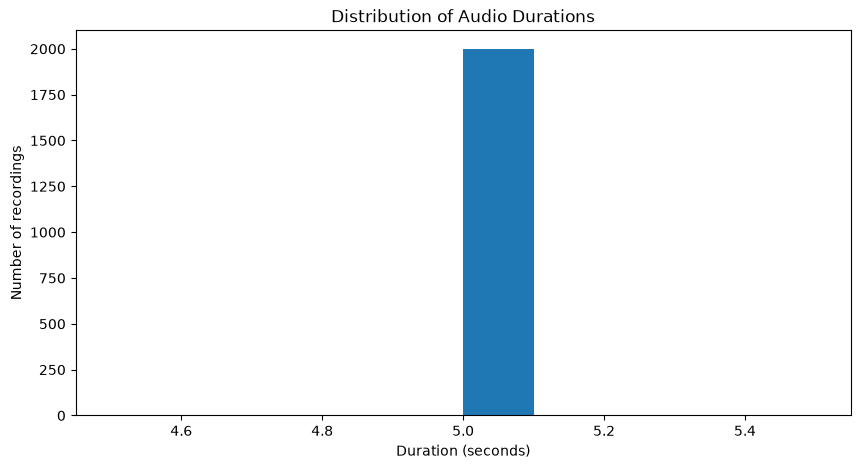

In [16]:
plt.figure(figsize=(10, 5))

plt.hist(durations, bins=10)

plt.xlabel("Duration (seconds)")
plt.ylabel("Number of recordings")
plt.title("Distribution of Audio Durations")

plt.show()

In [17]:
from IPython.display import Audio, display

sample_audio, sample_rate = sf.read(sample_file)

display(Audio(sample_audio, rate=sample_rate))

In [18]:
sample_filename = audio_files[0]

print("Audio filename:", sample_filename)

label_info = df[df["filename"] == sample_filename]

print("\nDataset label:")
print(label_info[["filename", "category", "target"]])

Audio filename: 1-100032-A-0.wav

Dataset label:
           filename category  target
0  1-100032-A-0.wav      dog       0


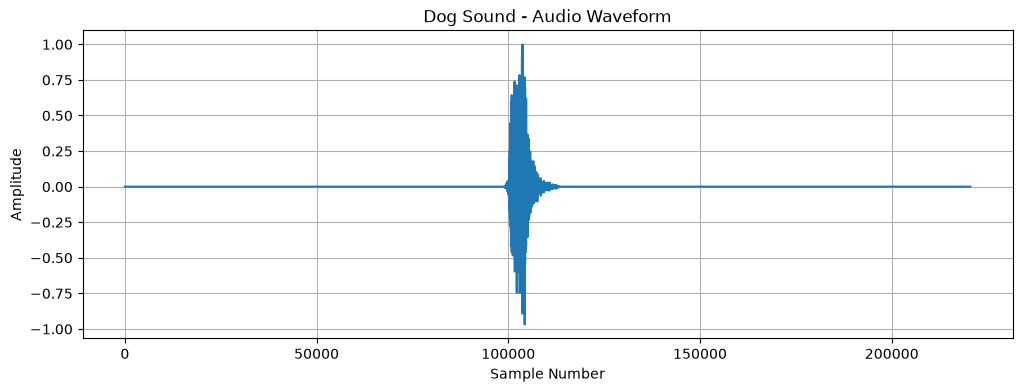

In [19]:
plt.figure(figsize=(12, 4))

plt.plot(sample_audio)

plt.title("Dog Sound - Audio Waveform")
plt.xlabel("Sample Number")
plt.ylabel("Amplitude")

plt.grid()
plt.show()

In [20]:
print("Audio Shape:", sample_audio.shape)
print("Sample Rate:", sample_rate)
print("Maximum Amplitude:", np.max(sample_audio))
print("Minimum Amplitude:", np.min(sample_audio))
print("Mean Amplitude:", np.mean(sample_audio))

Audio Shape: (220500,)
Sample Rate: 44100
Maximum Amplitude: 0.99884033203125
Minimum Amplitude: -0.9683837890625
Mean Amplitude: -1.4933545032596371e-07


In [21]:
random_samples = df.sample(5, random_state=42)

random_samples[["filename", "category", "target"]]

,filename,category,target
1860,5-221950-A-22.wav,clapping,22
353,1-79220-A-17.wav,pouring_water,17
1333,4-165845-A-45.wav,train,45
905,3-130330-A-22.wav,clapping,22
1289,4-157297-A-21.wav,sneezing,21


In [22]:
from IPython.display import Audio, display

for index, row in random_samples.iterrows():

    file_path = os.path.join(audio_path, row["filename"])

    audio, sr = sf.read(file_path)

    print("Filename:", row["filename"])
    print("Assigned Label:", row["category"])

    display(Audio(audio, rate=sr))

Filename: 5-221950-A-22.wav
Assigned Label: clapping


Filename: 1-79220-A-17.wav
Assigned Label: pouring_water


Filename: 4-165845-A-45.wav
Assigned Label: train


Filename: 3-130330-A-22.wav
Assigned Label: clapping


Filename: 4-157297-A-21.wav
Assigned Label: sneezing
